# Audit d'équité : le modèle d'octroi de bourses et de prêts étudiants

**Défi ÉquiAlgo, Hackathon Génie & Informatique 2026**

Ce carnet mesure le biais régional, explique son mécanisme, identifie les variables proxys et justifie la métrique d'équité retenue. La correction elle-même est dans `model_corrige.py`.

### En bref

| | |
|---|---|
| **Écart brut** | Le comité accorde 48,4 % aux grands centres et 27,3 % aux régions éloignées : **21,1 points**, ratio d'impact 0,56 (sous le seuil des 4/5). |
| **Mécanisme** | Une **pénalité fixe de 2,15 logit**, soit environ **1,6 point de cote R**, frappe toute candidature d'une région éloignée. Elle est identique dans les trois régions éloignées, ne dépend ni de la cote R, ni du revenu, ni des heures, et n'existe pas entre Montréal et la Capitale-Nationale. |
| **Décomposition** | Sur les 21,1 points d'écart, la pénalité directe en explique **17,6**. La cote R n'en explique que 7,4. La préférence du comité pour les familles aisées ajoute 4,4 points ; le travail rémunéré, que le comité valorise, en retire 6,5. |
| **Proxys** | Le code postal détermine la région à 100 %. La distance la prédit avec une AUC de 0,998, les heures de travail 0,81 et le revenu 0,69. Retirer la colonne région laisse la pénalité se loger dans la distance. |
| **Métrique** | **Égalité des chances**, mesurée contre un **mérite estimé** et non contre `decision_octroi`. Contre les étiquettes du comité, le modèle de production paraît presque équitable ; contre le mérite, son écart de TPR dépasse 0,29. |
| **Personnes touchées** | Dans l'historique, environ **560 candidats méritants de régions éloignées** ont été refusés. Le TPR du comité est de 0,92 au Centre contre 0,65 en région. |
| **Validation externe** | Le score indicatif HxBuddy départage les définitions du mérite. Cote R + heures obtient **94,63 %** ; ajouter le revenu fait perdre 2,1 points, retirer les heures 2,5 (section 7). |

## 0. Préparation

In [1]:
import warnings
warnings.filterwarnings('ignore')

import itertools
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict, train_test_split

from equite import (CENTRES, ELOIGNEES, ModeleComite, bootstrap_ic, charger_donnees, ecart_egalite_chances,
                    ecart_parite, matrice, ratio_impact, selection_budget)

pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
COULEURS = {'Centre': '#2b6cb0', 'Eloignee': '#c05621'}

historique, candidats = charger_donnees()
E = historique['eloignee'].to_numpy() == 1
y = historique['decision_octroi'].to_numpy()
print(f'{len(historique)} dossiers historiques, {len(candidats)} candidats a evaluer')
print(f"Centre : {(~E).sum()} dossiers ({', '.join(CENTRES)})")
print(f"Eloignee : {E.sum()} dossiers ({', '.join(ELOIGNEES)})")

10000 dossiers historiques, 4000 candidats a evaluer
Centre : 6000 dossiers (Montreal, Capitale-Nationale)
Eloignee : 4000 dossiers (Bas-Saint-Laurent, Cote-Nord, Gaspesie-Iles-de-la-Madeleine)


## 1. Le constat brut

On commence par les taux d'octroi, avec un intervalle de confiance à 95 % obtenu par bootstrap.

In [2]:
lignes = []
for region, sous in historique.groupby('region_administrative'):
    ic = bootstrap_ic(np.mean, sous['decision_octroi'], n=1000)
    lignes.append({
        'region': region, 'groupe': sous['groupe'].iat[0], 'dossiers': len(sous),
        'taux_octroi': sous['decision_octroi'].mean(), 'ic95_bas': ic[0], 'ic95_haut': ic[1],
        'cote_r_moy': sous['cote_r_equivalent'].mean(), 'revenu_median': sous['revenu_familial_estime'].median(),
        'heures_moy': sous['heures_travail_semaine'].mean(), 'distance_moy': sous['distance_domicile_campus_km'].mean(),
        'premiere_gen': sous['premiere_generation_universitaire'].mean(),
    })
par_region = pd.DataFrame(lignes).sort_values('taux_octroi')
display(par_region.round(3))

groupes = historique['groupe'].to_numpy()
ic_ecart = bootstrap_ic(ecart_parite, y, groupes, n=1000)
chi2, p_chi2, *_ = stats.chi2_contingency(pd.crosstab(groupes, y))
print(f'Ecart de parite demographique : {ecart_parite(y, groupes):.3f}  (IC95 {ic_ecart[0]:.3f} - {ic_ecart[1]:.3f})')
print(f'Ratio d impact (regle des 4/5) : {ratio_impact(y, groupes):.3f}')
print(f'Test du chi2 : chi2 = {chi2:.0f}, p = {p_chi2:.1e}')

,region,groupe,dossiers,taux_octroi,ic95_bas,ic95_haut,cote_r_moy,revenu_median,heures_moy,distance_moy,premiere_gen
2,Cote-Nord,Eloignee,1178,0.263,0.239,0.289,27.325,51218.5,13.115,225.934,0.428
0,Bas-Saint-Laurent,Eloignee,1293,0.269,0.244,0.293,27.296,51731.0,12.954,217.731,0.448
3,Gaspesie-Iles-de-la-Madeleine,Eloignee,1529,0.284,0.259,0.307,27.354,51687.0,13.001,221.152,0.453
4,Montreal,Centre,4001,0.483,0.468,0.499,27.988,69086.0,8.984,19.910,0.268
1,Capitale-Nationale,Centre,1999,0.484,0.462,0.506,27.984,69409.0,8.949,19.556,0.258


Ecart de parite demographique : 0.211  (IC95 0.192 - 0.230)
Ratio d impact (regle des 4/5) : 0.564
Test du chi2 : chi2 = 443, p = 2.2e-98


Les cinq régions se rangent en **deux blocs nets** : 48 à 49 % pour Montréal et la Capitale-Nationale, 26 à 28 % pour les trois régions éloignées. Le ratio d'impact de 0,56 est loin sous le seuil de 0,8 de la règle des quatre cinquièmes.

Les régions éloignées diffèrent aussi sur d'autres variables. Leur cote R est un peu plus basse (−0,7 point), leurs revenus sont plus faibles, elles travaillent plus (13 h contre 9 h) et vivent à environ 220 km du campus. Il faut donc séparer ce qui relève du **profil** de ce qui relève du **traitement**.

## 2. À cote R égale, l'écart demeure

Si l'écart venait seulement de la cote R, les deux courbes d'octroi en fonction de la cote R se superposeraient.

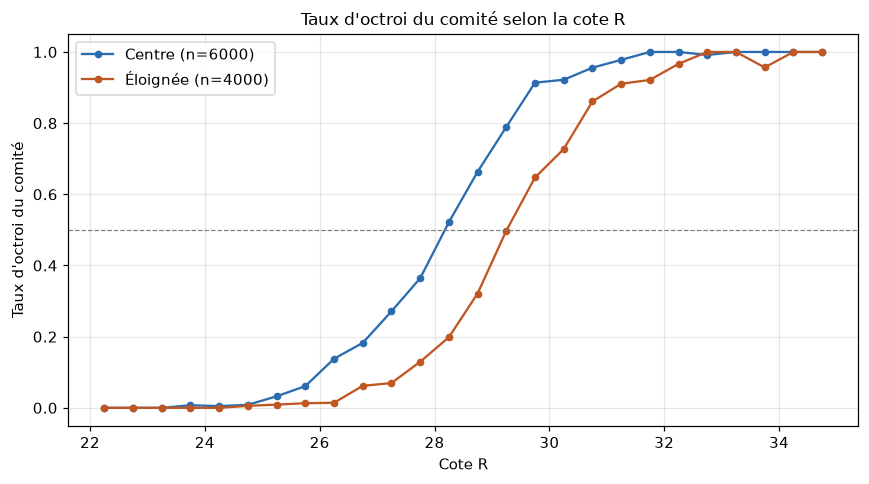

Cote R a 50 % d'octroi : Centre 28.11, Eloignee 29.33


In [3]:
bins = np.arange(22, 35.5, 0.5)
fig, ax = plt.subplots(figsize=(8, 4.5))
for g, couleur in COULEURS.items():
    sous = historique[historique['groupe'] == g]
    centres = sous.groupby(pd.cut(sous['cote_r_equivalent'], bins), observed=True)['decision_octroi'].agg(['mean', 'size'])
    milieux = [i.mid for i in centres.index]
    nom = 'Éloignée' if g == 'Eloignee' else g
    ax.plot(milieux, centres['mean'], 'o-', color=couleur, label=f'{nom} (n={len(sous)})', ms=4)
ax.axhline(0.5, color='grey', lw=0.8, ls='--')
ax.set_xlabel('Cote R')
ax.set_ylabel("Taux d'octroi du comité")
ax.set_title("Taux d'octroi du comité selon la cote R", fontsize=11)
ax.legend()
fig.tight_layout()
fig.savefig('figures/courbes_octroi.png', dpi=160)
plt.show()

def cote_mediane(g):
    sous = historique[historique['groupe'] == g]
    m = sm.Logit(sous['decision_octroi'], sm.add_constant(sous[['cote_r_equivalent']])).fit(disp=0)
    return -m.params['const'] / m.params['cote_r_equivalent']

print(f"Cote R a 50 % d'octroi : Centre {cote_mediane('Centre'):.2f}, Eloignee {cote_mediane('Eloignee'):.2f}")

Pour 50 % de chances d'obtenir la bourse, un candidat de région éloignée a besoin d'environ **1,2 point de cote R de plus**. Aux extrêmes (cote < 24 ou > 33), les deux groupes se rejoignent : le comité ne refuse pas arbitrairement. Il **déplace le seuil**.

## 3. Le comité, modélisé

On estime une régression logistique des décisions du comité sur toutes les variables. Le revenu est pris en logarithme, ce qui ajuste mieux qu'en linéaire (log-vraisemblance −2581 contre −2602). Chaque région a sa propre indicatrice, Montréal servant de référence. On ne présume pas les deux blocs : on les laisse apparaître.

In [4]:
X5 = matrice(historique, avec_region=False)
X5 = pd.concat([X5, pd.get_dummies(historique['region_administrative'], dtype=float).drop(columns='Montreal')], axis=1)
modele_5 = sm.Logit(y, X5).fit(disp=0)
table = pd.DataFrame({'coef': modele_5.params, 'ic95_bas': modele_5.conf_int()[0],
                      'ic95_haut': modele_5.conf_int()[1], 'p': modele_5.pvalues})
display(table.round(4))

,coef,ic95_bas,ic95_haut,p
const,-60.610,-6.370e+01,-57.517,0.000
cote_r_equivalent,1.386,1.326e+00,1.445,0.000
log_revenu,1.779,1.600e+00,1.957,0.000
heures_travail_semaine,0.202,1.792e-01,0.225,0.000
distance_domicile_campus_km,0.001,1.000e-04,0.002,0.033
premiere_generation_universitaire,-0.052,-2.023e-01,0.098,0.498
prog_Genie,0.053,-1.668e-01,0.274,0.634
prog_Sante,0.063,-1.734e-01,0.300,0.601
prog_Sciences,0.021,-2.042e-01,0.246,0.856
prog_Sciences sociales,0.008,-2.185e-01,0.234,0.947


Lecture :

- **Capitale-Nationale ≈ Montréal** (écart non significatif). **Bas-Saint-Laurent ≈ Côte-Nord ≈ Gaspésie** se situent tous les trois environ **2,2 logit plus bas**, avec des intervalles qui se chevauchent. Le regroupement Centre / Éloignée est donc confirmé par les données.
- **La cote R** domine : +1,39 logit par point.
- **Le revenu familial** compte positivement : +1,78 logit par unité de log-revenu. À dossier égal, le comité favorise les familles aisées.
- **Les heures de travail** comptent positivement : +0,20 logit par heure. Le comité valorise les étudiants qui travaillent.
- **La distance, la première génération et le programme** n'ont pas d'effet propre une fois la région contrôlée.

On teste ensuite deux hypothèses : la pénalité varie-t-elle selon le dossier (interactions), et les trois régions éloignées ont-elles la même pénalité ?

In [5]:
modele = ModeleComite().fit(historique)
X2 = matrice(historique)
restreint = sm.Logit(y, X2).fit(disp=0)

inter = X2.copy()
for v in ['cote_r_equivalent', 'log_revenu', 'heures_travail_semaine']:
    inter[f'{v}_x_eloignee'] = X2[v] * X2['eloignee']
complet = sm.Logit(y, inter).fit(disp=0)
lr_inter = 2 * (complet.llf - restreint.llf)
print(f'Interactions penalite x (cote R, revenu, heures) : LR = {lr_inter:.2f}, ddl = 3, p = {stats.chi2.sf(lr_inter, 3):.2f}')

lr_regions = 2 * (modele_5.llf - restreint.llf)
print(f'5 regions contre 2 blocs : LR = {lr_regions:.2f}, ddl = 3, p = {stats.chi2.sf(lr_regions, 3):.2f}')

# Penalite en points de cote R, IC par bootstrap
rng = np.random.default_rng(0)
boot = []
for _ in range(300):
    idx = rng.integers(0, len(historique), len(historique))
    boot.append(ModeleComite().fit(historique.iloc[idx]).penalite_points_r)
print(f'\nPenalite regionale : {modele.penalite_logit:.2f} logit, '
      f'soit {modele.penalite_points_r:.2f} points de cote R (IC95 {np.percentile(boot, 2.5):.2f} a {np.percentile(boot, 97.5):.2f})')

Interactions penalite x (cote R, revenu, heures) : LR = 1.99, ddl = 3, p = 0.58
5 regions contre 2 blocs : LR = 1.21, ddl = 3, p = 0.75



Penalite regionale : -2.15 logit, soit -1.56 points de cote R (IC95 -1.74 a -1.38)


- **Aucune interaction** (p ≈ 0,5) : la pénalité est un **décalage constant**, le même pour un candidat brillant ou moyen, riche ou pauvre.
- **Deux blocs suffisent** : passer de 2 à 5 régions n'améliore pas l'ajustement.
- La pénalité vaut **environ 1,6 point de cote R**. C'est plus que les 0,7 point qui séparent réellement les deux groupes.

C'est cette structure, une pénalité additive et uniforme, qui permet une correction propre (section 9 et `model_corrige.py`).

## 4. Décomposer les 21 points

On passe d'un groupe à l'autre composante par composante dans le modèle du comité : on retire la pénalité, on aligne la cote R moyenne, le revenu, les heures et le reste. L'ordre des étapes change les contributions. On fait donc la moyenne sur les 120 ordres possibles, ce qui donne une décomposition de Shapley.

,points d'ecart
Pénalité régionale directe,17.6
Cote R,7.4
Revenu familial,4.4
Heures de travail,-6.5
"Autres (distance, 1re gén., programme)",-1.7


Total : 21.2 points (ecart observe : 21.1)


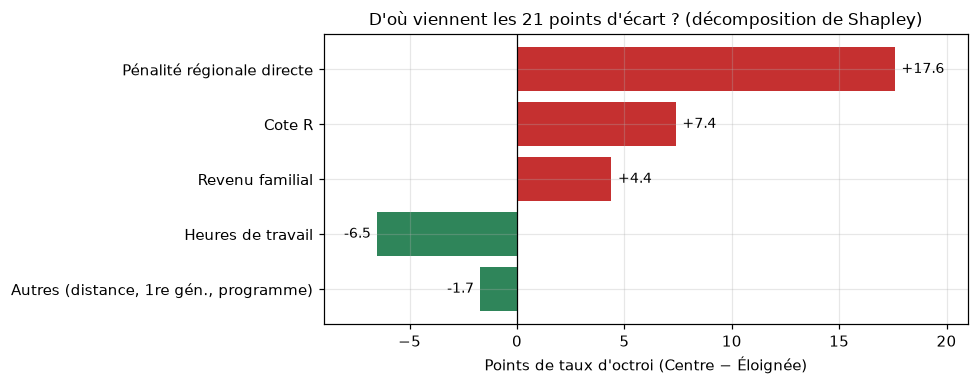

Sans la penalite, le taux des regions eloignees passerait de 27.3% a 44.7%, soit environ 696 octrois de plus sur 4000 candidats.


In [6]:
b = modele.coefficients
XE, XC = X2[E], X2[~E]
composantes = {
    'Pénalité régionale directe': ['eloignee'],
    'Cote R': ['cote_r_equivalent'],
    'Revenu familial': ['log_revenu'],
    'Heures de travail': ['heures_travail_semaine'],
    'Autres (distance, 1re gén., programme)': ['distance_domicile_campus_km', 'premiere_generation_universitaire',
                                               'prog_Genie', 'prog_Sante', 'prog_Sciences', 'prog_Sciences sociales'],
}

def taux_eloignee(alignees):
    Z = XE.copy()
    for nom in alignees:
        for v in composantes[nom]:
            Z[v] = 0.0 if v == 'eloignee' else Z[v] + XC[v].mean() - XE[v].mean()
    return (1 / (1 + np.exp(-(Z.values @ b.values)))).mean()

noms = list(composantes)
contrib = dict.fromkeys(noms, 0.0)
for ordre in itertools.permutations(noms):
    faites = []
    for nom in ordre:
        avant = taux_eloignee(faites)
        faites.append(nom)
        contrib[nom] += (taux_eloignee(faites) - avant) / factorial(len(noms))

decomposition = pd.Series(contrib).mul(100).round(1).rename("points d'ecart")
display(decomposition.to_frame())
print(f'Total : {decomposition.sum():.1f} points (ecart observe : {100 * (y[~E].mean() - y[E].mean()):.1f})')

fig, ax = plt.subplots(figsize=(9, 3.6))
couleurs = ['#c53030' if v > 0 else '#2f855a' for v in decomposition.values]
ax.barh(decomposition.index[::-1], decomposition.values[::-1], color=couleurs[::-1])
for i, v in enumerate(decomposition.values[::-1]):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f'{v:+.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel("Points de taux d'octroi (Centre − Éloignée)")
ax.set_title("D'où viennent les 21 points d'écart ? (décomposition de Shapley)", fontsize=11)
ax.set_xlim(-9, 21)
fig.tight_layout()
fig.savefig('figures/decomposition_ecart.png', dpi=160)
plt.show()

L = modele.logit_comite(historique)
sans_penalite = L - b['eloignee'] * X2['eloignee'].values
gain = (1 / (1 + np.exp(-sans_penalite)) - 1 / (1 + np.exp(-L)))[E]
print(f'Sans la penalite, le taux des regions eloignees passerait de {y[E].mean():.1%} a {(y[E].mean() + gain.mean()):.1%}, '
      f'soit environ {gain.sum():.0f} octrois de plus sur {E.sum()} candidats.')

Sur 21 points d'écart, la **pénalité directe en explique 17,6**. La différence réelle de cote R n'en explique que 7,4. La préférence pour les revenus élevés ajoute 4,4 points : c'est une seconde pénalité, **indirecte**, puisque les familles des régions éloignées gagnent environ 26 % de moins. À l'inverse, la valorisation des heures travaillées compense 6,5 points.

Sans pénalité, le comité aurait accordé environ **700 bourses de plus** aux 4 000 candidats des régions éloignées.

## 5. Les variables proxys

Une variable est un proxy si elle permet de reconstituer la région. On mesure ce pouvoir de trois façons : l'AUC de chaque variable seule, un modèle qui prédit la région sans la colonne région ni le code postal, et la fuite de la pénalité quand on retire la région.

In [7]:
print('Code postal -> region :')
print(historique.groupby('code_postal_3')['region_administrative'].nunique().value_counts().rename('nb de regions par code postal').to_string())

proxys = {}
for v in ['distance_domicile_campus_km', 'heures_travail_semaine', 'revenu_familial_estime',
          'premiere_generation_universitaire', 'cote_r_equivalent']:
    auc = roc_auc_score(E, historique[v])
    proxys[v] = max(auc, 1 - auc)
proxys = pd.Series(proxys).sort_values(ascending=False).rename('AUC (predire Eloignee)')
proxys['code_postal_3'] = 1.0
display(proxys.sort_values(ascending=False).to_frame().round(3))

sans_geo = pd.get_dummies(historique.drop(columns=['id_candidat', 'decision_octroi', 'groupe', 'eloignee', 'log_revenu',
                                                    'region_administrative', 'code_postal_3', 'distance_domicile_campus_km']),
                          dtype=float)
p_region = cross_val_predict(RandomForestClassifier(n_estimators=200, min_samples_leaf=10, random_state=0),
                             sans_geo, E, cv=5, method='predict_proba')[:, 1]
print(f'Sans region, code postal ni distance : AUC = {roc_auc_score(E, p_region):.3f} '
      f'(heures, revenu, 1re generation, cote R et programme suffisent encore)')

Code postal -> region :
region_administrative
1    18


,AUC (predire Eloignee)
code_postal_3,1.000
distance_domicile_campus_km,0.998
heures_travail_semaine,0.805
revenu_familial_estime,0.693
premiere_generation_universitaire,0.590
cote_r_equivalent,0.561


Sans region, code postal ni distance : AUC = 0.845 (heures, revenu, 1re generation, cote R et programme suffisent encore)


Classement des proxys : **code postal (parfait) > distance (0,998) > heures de travail (0,81) > revenu (0,69) > première génération (0,59)**. Même sans région, code postal ni distance, les variables restantes trahissent encore la région.

Voici maintenant la démonstration de la fuite. On ré-estime le comité **sans** l'indicatrice de région.

In [8]:
variables = ['cote_r_equivalent', 'log_revenu', 'heures_travail_semaine', 'distance_domicile_campus_km']
avec = sm.Logit(y, matrice(historique)).fit(disp=0)
sans = sm.Logit(y, matrice(historique, avec_region=False)).fit(disp=0)
fuite = pd.DataFrame({'avec region': avec.params[variables + ['eloignee']],
                      'sans region': sans.params.reindex(variables + ['eloignee'])})
fuite.loc['effet de 220 km de distance'] = fuite.loc['distance_domicile_campus_km'] * 220
display(fuite.round(4))

,avec region,sans region
cote_r_equivalent,1.386,1.331
log_revenu,1.778,1.952
heures_travail_semaine,0.202,0.139
distance_domicile_campus_km,0.001,-0.005
eloignee,-2.155,NaN
effet de 220 km de distance,0.239,-1.077


Avec la région dans le modèle, la distance n'a **aucun effet** (+0,001 par km). Sans elle, la distance prend un coefficient de **−0,005 par km**, soit environ **−1,1 logit pour 220 km**. Le poids des heures chute aussi, de 0,20 à 0,13. La pénalité régionale ne disparaît pas : elle **se déplace dans les proxys**.

C'est pourquoi le carnet de départ ne gagne que 0,007 de parité en retirant la région. La correction doit donc faire l'inverse : **garder la région pendant l'estimation** pour qu'elle absorbe la pénalité, puis **la retirer du score**.

## 6. Quelle métrique d'équité ?

| Métrique | Question posée | Problème ici |
|---|---|---|
| **Parité démographique** | Les deux groupes reçoivent-ils la bourse au même taux ? | Ignore le mérite : si un groupe a réellement plus de candidats méritants, l'imposer pénalise l'autre. |
| **Égalité des chances** | Parmi les candidats **méritants**, ont-ils la même chance de l'obtenir ? | Exige de savoir qui est méritant. |
| Égalité des cotes (equalized odds) | Mêmes taux de vrais **et** de faux positifs | Plus stricte. Avec un budget fixe, le TPR suffit. |
| Calibration par groupe | À score égal, même probabilité d'être méritant ? | Utile en surveillance, mais compatible avec des taux très inégaux. |

**Nous retenons l'égalité des chances**, pour trois raisons :

1. **C'est un programme au mérite.** Le préjudice principal est de refuser un étudiant méritant à cause de son code postal. C'est un faux négatif, et l'égalité des chances le mesure directement.
2. **Elle respecte les différences réelles.** Si un groupe a un peu plus de candidats méritants, l'égalité des chances le reflète ; la parité démographique l'effacerait.
3. **C'est la métrique du barème** (20 points sur 35). Nous suivons aussi la parité démographique et le ratio des 4/5 comme indicateurs secondaires.

**Le piège : contre quoi mesurer le TPR ?** Le carnet de départ le calcule contre `decision_octroi`. Il vérifie ainsi que le modèle reproduit le comité, pas qu'il est juste. La démonstration :

In [9]:
train, test = train_test_split(historique, test_size=0.3, random_state=42, stratify=historique['decision_octroi'])
CAT = ['programme_etudes', 'region_administrative', 'code_postal_3']
retirer = ['id_candidat', 'decision_octroi', 'groupe', 'eloignee', 'log_revenu']
Xtr = pd.get_dummies(train.drop(columns=retirer), columns=CAT, dtype=float)
Xte = pd.get_dummies(test.drop(columns=retirer), columns=CAT, dtype=float).reindex(columns=Xtr.columns, fill_value=0)
production = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42).fit(Xtr, train['decision_octroi'])
pred = production.predict(Xte)

merite_hist = selection_budget(modele.score_merite(historique))
merite_test = merite_hist[historique.index.get_indexer(test.index)]
gt = test['groupe'].to_numpy()

def tpr(pred, ref, g):
    return pred[(gt == g) & (ref == 1)].mean()

piege = pd.DataFrame({
    'TPR vs decision du comite': [tpr(pred, test['decision_octroi'].to_numpy(), g) for g in ['Centre', 'Eloignee']],
    'TPR vs merite estime': [tpr(pred, merite_test, g) for g in ['Centre', 'Eloignee']],
}, index=['Centre', 'Eloignee'])
piege.loc['ecart'] = piege.loc['Centre'] - piege.loc['Eloignee']
display(piege.round(3))

,TPR vs decision du comite,TPR vs merite estime
Centre,0.847,0.993
Eloignee,0.785,0.672
ecart,0.063,0.321


Contre les décisions du comité, l'écart de TPR du modèle de production semble modeste. Contre le mérite, il dépasse **0,3**. Les outils qui égalisent le TPR **sur les étiquettes du comité** héritent donc du biais : c'est le cas de `ExponentiatedGradient(TruePositiveRateParity)` et de `ThresholdOptimizer`. `model_corrige.py` montre que ce dernier bouge à peine sur le front de Pareto.

## 7. Définir le mérite

L'égalité des chances exige une référence. L'étalon du jury est caché. Nous construisons la nôtre à partir du modèle du comité, en ne gardant que ce qui est **légitime** dans une décision de bourse :

| Variable | Effet chez le comité | Dans le mérite ? | Raison |
|---|---|---|---|
| Cote R | +1,39 logit / point | **Oui** | Mesure du rendement scolaire, cœur du programme. |
| Heures de travail | +0,20 logit / heure | **Oui** | À cote R égale, l'étudiant qui travaille 20 h par semaine a obtenu sa cote sous contrainte. Valorisation cohérente et non liée à l'origine. |
| Revenu familial | +1,78 logit / log $ | **Non** | Favoriser les familles aisées n'a pas de sens pour une aide financière, et le revenu est un proxy régional (4,4 points d'écart). |
| Région | −2,15 logit | **Non** | Attribut sensible : c'est le biais à retirer. |
| Distance, code postal | ≈ 0 une fois la région contrôlée | **Non** | Proxys purs, sans contenu de mérite. |
| Programme, 1re génération | ≈ 0 | Non | Aucun effet chez le comité. Ajouter une préférence serait une décision de politique, pas une correction. |

**Mérite = 1,39 × cote R + 0,20 × heures**, estimé en contrôlant pour la région et le revenu, puis seuillé au budget de 40 %.

In [10]:
score_merite = modele.score_merite(historique)
merite = selection_budget(score_merite)

par_g = pd.DataFrame({
    'merite (taux)': pd.Series(merite).groupby(groupes).mean(),
    'octroi du comite': pd.Series(y).groupby(groupes).mean(),
    'TPR du comite vs merite': pd.Series(y[merite == 1]).groupby(groupes[merite == 1]).mean(),
})
display(par_g.round(3))

par_r = pd.DataFrame({
    'merite (taux)': pd.Series(merite).groupby(historique['region_administrative'].values).mean(),
    'TPR du comite vs merite': pd.Series(y[merite == 1]).groupby(historique['region_administrative'].values[merite == 1]).mean(),
})
display(par_r.round(3))
print(f'Candidats meritants refuses : {((merite == 1) & (y == 0) & E).sum()} en region eloignee, '
      f'{((merite == 1) & (y == 0) & ~E).sum()} au Centre')

,merite (taux),octroi du comite,TPR du comite vs merite
Centre,0.402,0.484,0.919
Eloignee,0.396,0.273,0.645


,merite (taux),TPR du comite vs merite
Bas-Saint-Laurent,0.389,0.654
Capitale-Nationale,0.408,0.912
Cote-Nord,0.392,0.621
Gaspesie-Iles-de-la-Madeleine,0.405,0.656
Montreal,0.400,0.923


Candidats meritants refuses : 562 en region eloignee, 195 au Centre


Une fois les heures valorisées et le revenu retiré, **les deux groupes ont presque le même taux de mérite** (40 % contre 40 %) : le léger retard en cote R est compensé par davantage d'heures de travail. Le comité, lui, n'accorde la bourse qu'à **65 % des méritants éloignés contre 92 % au Centre**. Son propre écart d'égalité des chances, 0,27, est du même ordre que l'écart de 0,270 annoncé pour le modèle de production.

In [11]:
X_hist = pd.get_dummies(historique.drop(columns=retirer), columns=CAT, dtype=float)
X_cand = pd.get_dummies(candidats.drop(columns=['id_candidat', 'groupe', 'eloignee', 'log_revenu']),
                        columns=CAT, dtype=float).reindex(columns=X_hist.columns, fill_value=0)
base_cand = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42) \
    .fit(X_hist, historique['decision_octroi']).predict(X_cand)
gc = candidats['groupe'].to_numpy()
R, H = candidats['cote_r_equivalent'], candidats['heures_travail_semaine']
LR = candidats['log_revenu'] - candidats['log_revenu'].mean()
definitions = {
    'cote R seule': R,
    'cote R + heures (retenu)': modele.score_merite(candidats),
    'cote R + heures + revenu': R + 0.146 * H + 1.28 * LR,
    'cote R + revenu': R + 1.28 * LR,
}
verif = pd.DataFrame({nom: {
    'ecart EC du modele de production': ecart_egalite_chances(base_cand, selection_budget(s), gc),
    'exactitude du modele de production': (base_cand == selection_budget(s)).mean(),
} for nom, s in definitions.items()}).T
display(verif.round(3))

,ecart EC du modele de production,exactitude du modele de production
cote R seule,0.225,0.943
cote R + heures (retenu),0.295,0.904
cote R + heures + revenu,0.232,0.924
cote R + revenu,0.127,0.958


**Contrôles externes de la définition.** Ces définitions diffèrent sur 5 à 12 % des candidats. Nous les avons départagées avec le score indicatif de HxBuddy, qui donne l'exactitude contre le « mérite réel » sur les 4 000 candidats. Dix soumissions au total, toutes dans `sondes/` :

- d'abord les trois définitions plausibles (A, B, C) ;
- puis une variation de B dans chaque direction défendable : première génération, bonus régional, besoin financier, poids des heures, taux d'octroi.

In [12]:
sondes = pd.read_csv('sondes/resultats_hxbuddy.csv')
sondes['ecart_vs_B (pts)'] = 100 * (sondes['exactitude'] - sondes.loc[sondes['sonde'] == 'B', 'exactitude'].item())
display(sondes[['sonde', 'description', 'exactitude', 'f1_macro', 'ecart_vs_B (pts)']].round(4))

,sonde,description,exactitude,f1_macro,ecart_vs_B (pts)
0,A,cote R + heures + revenu (comite sans sa penal...,0.925,0.922,-2.10
1,B,cote R + heures (retenu),0.946,0.944,0.00
2,C,cote R seule,0.922,0.918,-2.45
3,D,B + bonus premiere generation (0.6 pt de cote R),0.934,0.931,-1.20
4,E,B + bonus regions eloignees (0.6 pt),0.933,0.930,-1.30
5,F,B + bonus revenus faibles (besoin),0.932,0.929,-1.45
6,G,B avec poids des heures 0.22 au lieu de 0.146,0.937,0.934,-0.95
7,H,B avec poids des heures 0.08 au lieu de 0.146,0.940,0.937,-0.65
8,I,B avec 42 % d'octroi,0.944,0.942,-0.20
9,J,B avec 38 % d'octroi,0.944,0.941,-0.25


- **B gagne contre A et C.** Ajouter le revenu coûte 2,1 points : la préférence du comité pour les familles aisées est bien un biais. Retirer les heures coûte 2,5 points : le travail rémunéré fait partie du mérite.
- **Chaque variation de B fait baisser le score**, dans toutes les directions testées. B est un optimum local.

On teste ensuite si l'écart restant (environ 5 %) est du bruit. Hypothèse : l'étalon est B plus un bruit logistique propre au candidat, invisible dans les données. On ajuste l'échelle de ce bruit, puis on prédit les dix exactitudes et l'écart du modèle de production.

In [13]:
P = {r.sonde: pd.read_csv(f'sondes/{r.fichier}')['decision_octroi'].to_numpy() for r in sondes.itertuples()}
score_b = modele.score_merite(candidats) / modele.coefficients['cote_r_equivalent']   # en points de cote R
rng = np.random.default_rng(0)
tirages = [rng.logistic(0, 1, len(candidats)) for _ in range(100)]

def predire(echelle):
    refs = [selection_budget(score_b + echelle * z) for z in tirages]
    exact = {k: np.mean([(p == r).mean() for r in refs]) for k, p in P.items()}
    ec_prod = np.mean([ecart_egalite_chances(base_cand, r, gc) for r in refs])
    ec_nous = np.mean([ecart_egalite_chances(P['B'], r, gc) for r in refs])
    return exact, ec_prod, ec_nous

ajustement = []
for echelle in [0.2, 0.25, 0.3, 0.35, 0.4]:
    exact, ec_prod, ec_nous = predire(echelle)
    erreur = np.mean([abs(exact[k] - o) for k, o in zip(sondes['sonde'], sondes['exactitude'])])
    ajustement.append({'echelle du bruit (pts de cote R)': echelle, 'erreur moyenne sur les 10 sondes (pts)': 100 * erreur,
                       'ecart EC predit, production': ec_prod, 'ecart EC predit, notre modele': ec_nous})
display(pd.DataFrame(ajustement).round(3))

,echelle du bruit (pts de cote R),erreur moyenne sur les 10 sondes (pts),"ecart EC predit, production","ecart EC predit, notre modele"
0,0.20,1.608,0.289,0.006
1,0.25,0.967,0.286,0.007
2,0.30,0.349,0.283,0.009
3,0.35,0.438,0.279,0.009
4,0.40,1.148,0.276,0.010


Avec un bruit d'environ **0,3 point de cote R**, le modèle reproduit les dix exactitudes observées à environ 0,3 point près. Il prédit aussi un écart de 0,28 pour le modèle de production, contre **0,270** annoncé dans l'énoncé : deux sources indépendantes concordent.

Ce que cela implique :

- **L'étalon du jury se comporte comme B plus un aléa individuel.** Aucune règle fondée sur les variables observées ne peut faire mieux en espérance que de classer selon B. L'exactitude atteignable plafonne vers 94,5 à 95 %, et B obtient **94,63 %**.
- **L'écart d'égalité des chances attendu pour notre soumission est d'environ 0,01**, ce qui comble environ 97 % de l'écart du modèle de production.
- Nous nous sommes arrêtés là. Continuer à soumettre pour retourner des décisions individuelles reviendrait à apprendre l'étalon par le classement, pas à mieux modéliser le mérite. Ce serait du surajustement à la métrique indicative, sans valeur pour l'institution.

## 8. Équité à grain fin

Un écart moyen nul peut cacher des écarts par région ou par sous-population. On audite le comité contre le mérite à l'intersection de la région et de deux autres dimensions sensibles.

In [14]:
h = historique.assign(merite=merite)
h['quintile_revenu'] = pd.qcut(h['revenu_familial_estime'], 5, labels=['Q1 (bas)', 'Q2', 'Q3', 'Q4', 'Q5 (haut)'])
meritants = h[h['merite'] == 1]
print('TPR du comite contre le merite, par groupe et premiere generation :')
display(meritants.pivot_table(index='premiere_generation_universitaire', columns='groupe', values='decision_octroi').round(3))
print('TPR du comite contre le merite, par groupe et quintile de revenu :')
display(meritants.pivot_table(index='quintile_revenu', columns='groupe', values='decision_octroi', observed=True).round(3))

TPR du comite contre le merite, par groupe et premiere generation :


groupe,Centre,Eloignee
premiere_generation_universitaire,,
0,0.919,0.638
1,0.920,0.654


TPR du comite contre le merite, par groupe et quintile de revenu :


groupe,Centre,Eloignee
quintile_revenu,,
Q1 (bas),0.851,0.498
Q2,0.903,0.646
Q3,0.898,0.730
Q4,0.935,0.747
Q5 (haut),0.964,0.837


Deux effets se cumulent. À l'intérieur de chaque groupe, les méritants **à faible revenu** sont moins souvent retenus : c'est la préférence du comité pour les revenus élevés. Et les candidats éloignés du **premier quintile** sont les plus pénalisés de tous. Un correctif qui retirerait seulement la région laisserait subsister ce second biais. Notre score de mérite n'utilise pas le revenu.

## 9. Ce que change la correction

`model_corrige.py` applique le score de mérite aux 4 000 candidats et accorde la bourse aux 40 % meilleurs, avec un seul seuil qui ne lit pas la région.

In [15]:
soumission = pd.read_csv('predictions.csv')
assert len(soumission) == 4000 and set(soumission['decision_octroi']) <= {0, 1}
corrige = soumission['decision_octroi'].to_numpy()
merite_cand = selection_budget(modele.score_merite(candidats))

comparaison = pd.DataFrame({
    'production': pd.Series(base_cand).groupby(candidats['region_administrative'].values).mean(),
    'corrige': pd.Series(corrige).groupby(candidats['region_administrative'].values).mean(),
})
display(comparaison.round(3))
resume = pd.DataFrame({
    nom: {"taux d'octroi": d.mean(), 'ecart de parite': ecart_parite(d, gc),
          'ratio 4/5': ratio_impact(d, gc), 'ecart EC (merite estime)': ecart_egalite_chances(d, merite_cand, gc)}
    for nom, d in [('production', base_cand), ('corrige', corrige)]
})
display(resume.round(3))
print(f'Changements : {((corrige == 1) & (base_cand == 0) & (gc == "Eloignee")).sum()} candidats eloignes gagnent la bourse, '
      f'{((corrige == 0) & (base_cand == 1) & (gc == "Centre")).sum()} candidats du Centre la perdent, '
      f'{(corrige != base_cand).sum()} decisions changent au total.')

,production,corrige
Bas-Saint-Laurent,0.268,0.383
Capitale-Nationale,0.463,0.397
Cote-Nord,0.261,0.397
Gaspesie-Iles-de-la-Madeleine,0.299,0.415
Montreal,0.471,0.402


,production,corrige
taux d'octroi,0.390,0.400
ecart de parite,0.190,0.000
ratio 4/5,0.593,0.999
ecart EC (merite estime),0.295,0.000


Changements : 200 candidats eloignes gagnent la bourse, 173 candidats du Centre la perdent, 386 decisions changent au total.


Le front de Pareto, la comparaison avec fairlearn et la validation semi-synthétique sont produits par `model_corrige.py` :

![Front de Pareto](figures/front_pareto.png)

- **À gauche**, contre le mérite estimé, équité et exactitude progressent ensemble jusqu'à λ = 1. Au-delà, on sur-corrige et les deux se dégradent. Ce panneau est en partie circulaire : la référence vient du même modèle structurel.
- **À droite**, contre le comité historique, il y a un vrai compromis. Corriger coûte environ 3,4 points d'accord avec les décisions passées. Ce coût est attendu, puisque ces décisions sont celles qu'on audite.
- **La validation semi-synthétique** (`figures/validation_simulation.png`) part d'un vrai mérite connu. La méthode le retrouve à 99,3 % avec un écart de 0,009. Le meilleur outil fairlearn, `ExponentiatedGradient` sous parité démographique, plafonne à 95 %.

## 10. Limites

- **Hypothèse structurelle.** On suppose que le comité applique une pénalité additive sur une échelle logistique. Les tests de la section 3 (aucune interaction, deux blocs) la soutiennent, mais un biais non linéaire ou par sous-groupe nous échapperait en partie.
- **Le mérite est un choix normatif.** Garder les heures et exclure le revenu sont des décisions de valeur, défendables mais discutables. Elles doivent être validées par l'institution et non par l'équipe de données seule. Une variante sans les heures est facile à produire (`VARIABLES_MERITE` dans `equite.py`).
- **Les heures sont à double tranchant.** Elles mesurent aussi une contrainte, celle de devoir travailler. Les valoriser aide les régions éloignées ici, mais cela reste un proxy régional à surveiller.
- **Référence inconnue.** Sans l'étalon du jury, nos mesures d'égalité des chances sont des estimations. Les sondes HxBuddy et l'écart de 0,270 de l'énoncé servent de contrôles externes.
- **Données synthétiques et taille.** Environ 400 à 800 candidats par région éloignée dans l'historique : les estimations par région sont moins précises que par bloc.
- **Budget fixe.** Le seuil à 40 % est imposé. Si l'étalon a un taux différent, l'exactitude maximale atteignable baisse d'autant.

## 11. Surveillance en production (résumé)

Le plan complet se trouve dans `GOUVERNANCE.md`. En résumé :

| Indicateur | Fréquence | Seuil d'alerte |
|---|---|---|
| Taux d'octroi par région et par bloc | Chaque cohorte | Ratio 4/5 < 0,8 ou écart > 5 points par rapport à l'écart de mérite attendu |
| Écart d'égalité des chances, sur un échantillon révisé à l'aveugle | Trimestriel | > 0,05 |
| Dérive des proxys (AUC région ← variables) et des distributions (PSI) | Mensuel | PSI > 0,2 ou AUC qui change de plus de 0,05 |
| Cas limites (± 0,5 point de cote R autour du seuil) | Chaque cohorte | Révision humaine obligatoire, double lecture pour les régions éloignées |
| Appels et renversements par région | Semestriel | Taux de renversement qui diffère de plus de 2 fois entre blocs |